# View Results from the Nested Optimization

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from nested.optimize_utils import PopulationAnnealing, OptimizationHistory, OptimizationReport

In [26]:
file_path = 'data/nested_optimization_history_PopulationAnnealing_hgrsnn_wo_flush.hdf5'

history = OptimizationHistory(file_path=file_path)
report = OptimizationReport(file_path=file_path)

report.report_best()

OptimizationHistory: loading 150 generations from file: data/nested_optimization_history_PopulationAnnealing_hgrsnn_wo_flush.hdf5 took 15.34 s
params:
alpha_0: 0.1654795456534371
threshold_0: 1.9754057030773187
alpha_1: 0.4548750898844419
threshold_1: 0.7024534625944623
alpha_2: 0.3498470113868973
threshold_2: 0.6362622557055193
lr: 0.08385539148092415
features:
avg_val_auc: 0.14615728609641837
avg_val_loss: 0.6952274490660186
objectives:
avg_val_loss: 0.6952274490660186
avg_val_auc: 0.14615728609641837


/Users/rahul/Documents/Milstein_Lab/nested/optimize_utils.py:328: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/rahul/Documents/Milstein_Lab/nested/optimize_utils.py:365: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/rahul/Documents/Milstein_Lab/nested/optimize_utils.py:411: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/rahul/Documents/Milstein_Lab/nested/optimize_utils.py:469: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/Users/rahul/Documents/Milstein_Lab/nested/optimize_utils.py:547: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


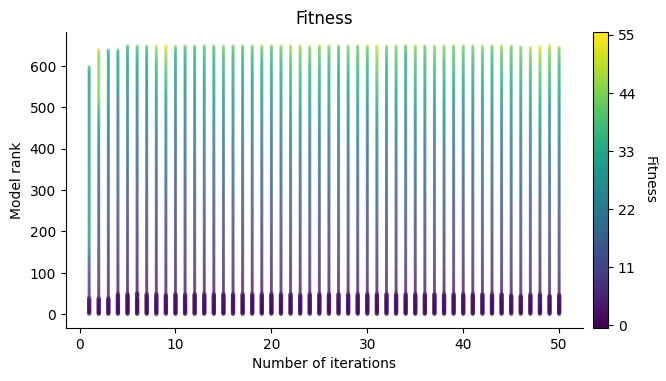

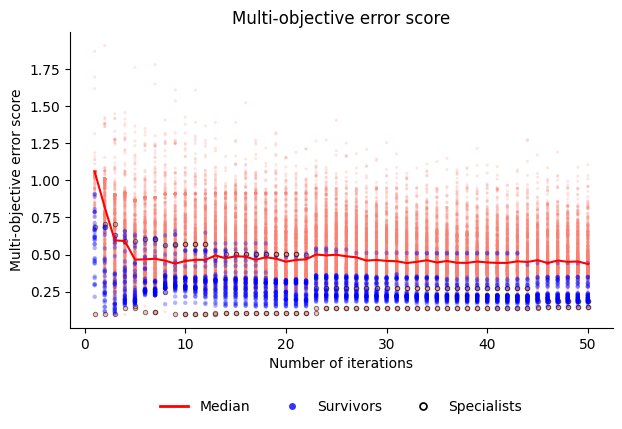

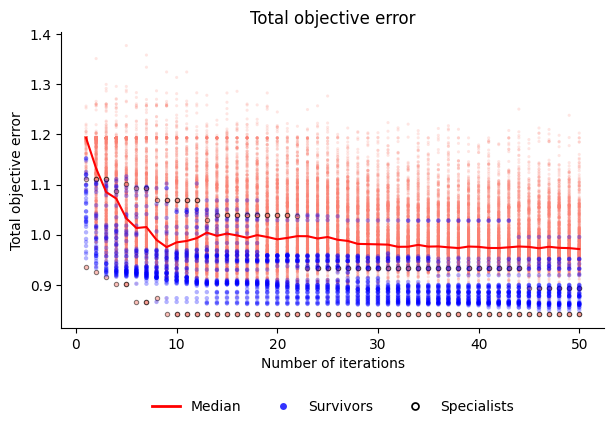

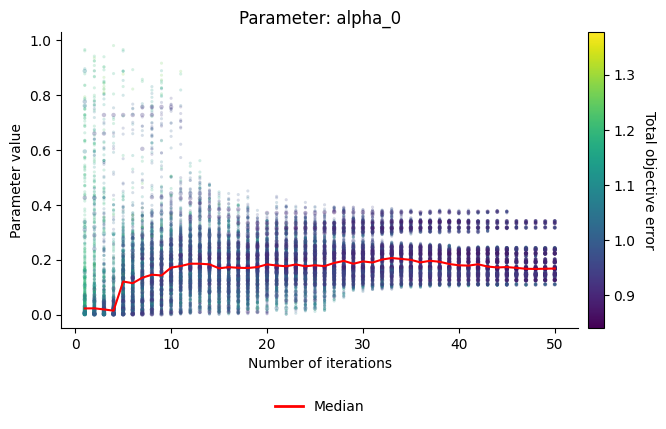

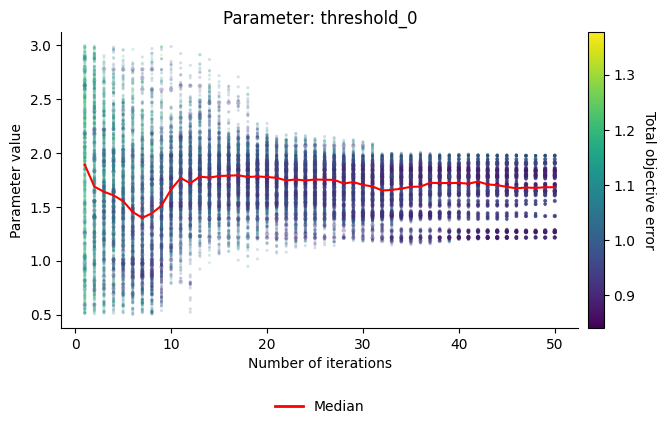

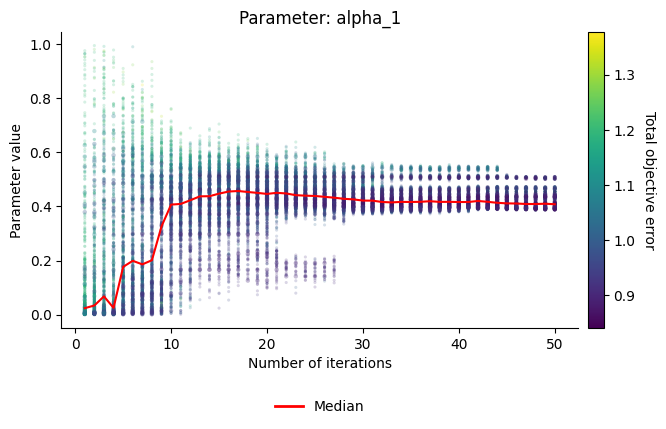

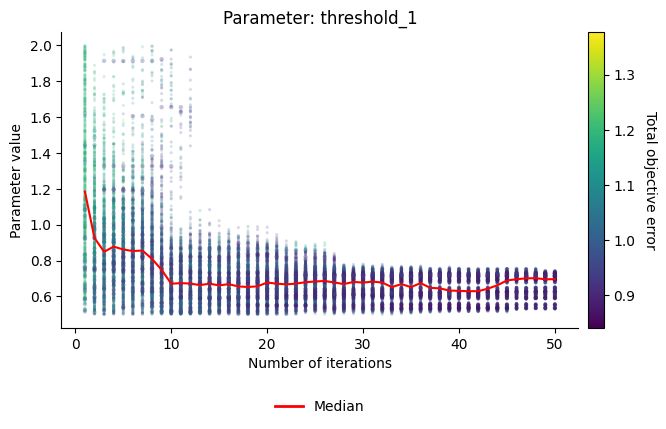

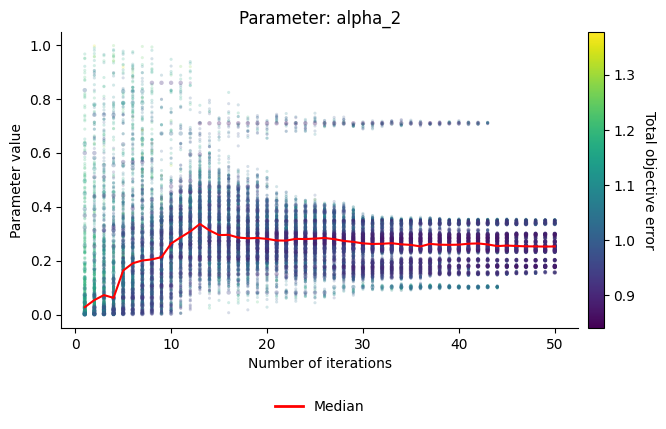

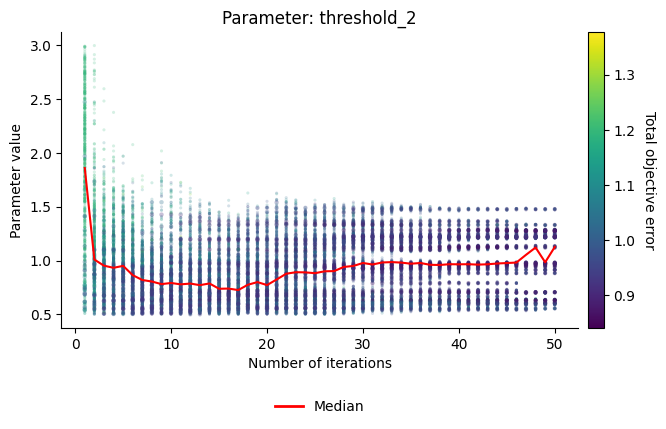

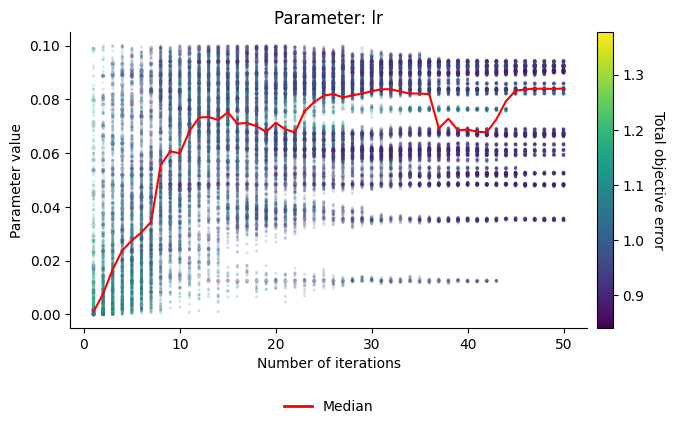

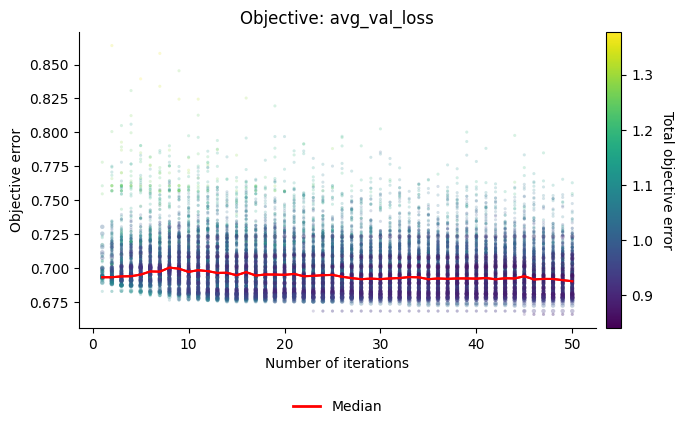

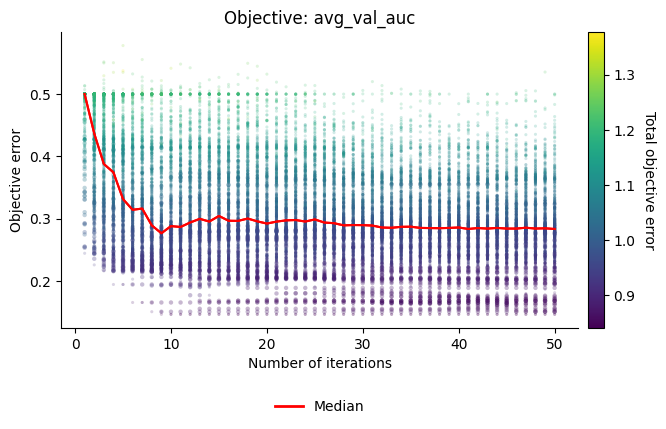

In [27]:
history.plot(['parameters', 'objectives'], energy_scale='linear', energy_color='absolute');

## Hyperparameter Importance

In [8]:
from nested.lsa import *
from nested.optimize_utils import *

In [20]:
file_path = 'data/nested_optimization_history_PopulationAnnealing_hgrsnn.hdf5'

history = OptimizationHistory(file_path=file_path)
sa = ParameterSensitivity(history=history)


OptimizationHistory: loading 150 generations from file: data/nested_optimization_history_PopulationAnnealing_hgrsnn.hdf5 took 13.35 s


/var/folders/b_/g86mqb050xqcjd0hx6_l6j780000gn/T/ipykernel_42058/2831597436.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


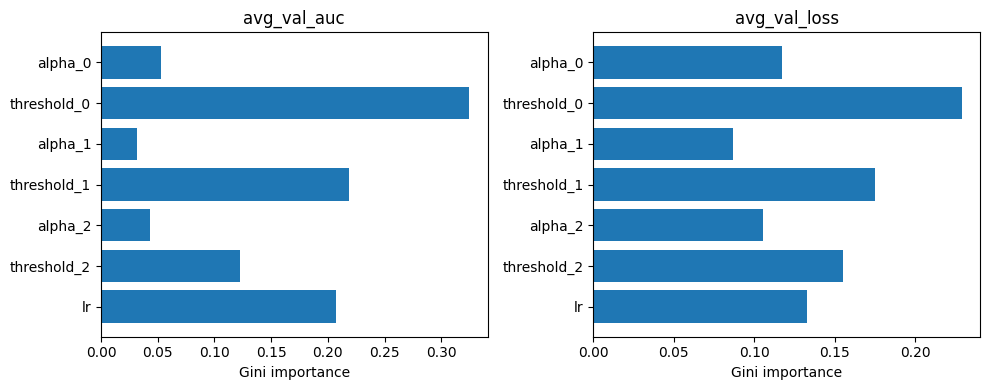

In [23]:
importance = sa.compute_parameter_importances()

# importance is a 2d array of shape (num_params, num_features):
# rows = hyperparameters, columns = output features
param_names = sa.param_names
feature_names = sa.feature_names

fig, axes = plt.subplots(1, len(feature_names), figsize=(5 * len(feature_names), 4), squeeze=False)
for i, feature in enumerate(feature_names):
    ax = axes[0, i]
    ax.barh(np.arange(len(param_names)), importance[:, i])
    ax.set_yticks(np.arange(len(param_names)))
    ax.set_yticklabels(param_names)
    ax.invert_yaxis()  # first param at top
    ax.set_xlabel('Gini importance')
    ax.set_title(feature)
fig.tight_layout()
fig.show()